# Reading AVS-UCD meshes with pyramids-mesh

**AVS-UCD** (*Unstructured Cell Data*) is the ASCII mesh format of the AVS visualization system, also emitted by mesh generators such as [LaGriT](https://github.com/lanl/LaGriT). It lists nodes, then cells of mixed type, then optional node/cell data.

`driver="avsucd"` reads it. Coordinates are model-local — **`crs=None`**.

This sample, `02_tet_mesh.inp` from LaGriT, is deliberately instructive: it is a **tetrahedral (volumetric)** mesh — 1122 nodes, 4800 tets. A `UgridDataset` models a 2D *surface*, so each tet face is flattened into the plane. That projection produces many overlapping and **degenerate (zero-area)** faces, and pyramids warns about it on read. This notebook shows both how to read such a file *and* why a volumetric mesh is the wrong shape for a surface container.

> Source: LANL LaGriT tutorial data, BSD-3-Clause.

## Set up plotting

pyramids draws through **cleopatra** (its matplotlib layer). Under a headless `Agg` backend a figure renders but is never shown, so we add a tiny `show()` helper that captures the current figure and embeds it as a PNG after every plot.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib; matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display
def show():
    from io import BytesIO
    buf = BytesIO(); plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight"); plt.close("all"); buf.seek(0)
    display(Image(data=buf.read()))

## Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
import numpy as np
import geopandas as gpd
from pathlib import Path
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")  # resolved relative to THIS notebook
DATA

WindowsPath('../../examples/data')

## Quickstart: read the AVS-UCD file

`driver="avsucd"` parses the UCD grammar. Expect a burst of warnings about re-wound and **degenerate** faces — the direct consequence of flattening a 3D tet mesh into 2D. They are warnings, not errors.

The one rule that matters: **pass a `pathlib.Path`, never a `str`** — `read_file` keys its driver dispatch off the `Path` type. `UgridDataset.read_file(...)` returns a `UgridDataset`, the in-memory UGRID container every pyramids-mesh driver produces.

In [3]:
ds = UgridDataset.read_file(DATA / "avsucd" / "02_tet_mesh.inp", driver="avsucd")
ds

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 1877 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 1959 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=1122, n_face=4800, n_edge=0, variables=['node_z'])

## What did we get?

A few scalar properties describe the dataset at a glance: node and face counts, the coordinate reference system, and the planar bounding box.

In [4]:
print("n_node :", ds.n_node)
print("n_face :", ds.n_face)
print("crs    :", ds.crs)
print("epsg   :", ds.epsg)
print("data   :", ds.data_variable_names)
print("bounds :", ds.bounds)

n_node : 1122
n_face : 4800
crs    : None
epsg   : None
data   : ['node_z']
bounds : (0.0, 0.0, 100.0, 50.0)


`crs`/`epsg` are `None`. The projected mesh reports 1122 nodes and 4800 faces over a `100×50` extent, with a `node_z` variable — the z-coordinate that the 2D projection discards geometrically but keeps as data.

### Summary table

`ds.summary()` returns a pandas `DataFrame` with per-variable statistics (count / min / max / mean / std). It reports `node_z`, whose range hints at the original 3D extent.

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,1122,0.0,80.0,40.0,24.494897


## The mesh geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the **face-node connectivity**, an `(n_face, k)` integer table where `k` is the largest number of nodes any face has. Triangles fill 3 columns; quadrilaterals fill 4 (a shorter face pads the spare slot). `face_areas` and `face_centroids` are derived on demand.

In [6]:
mesh = ds.mesh
fnc = mesh.face_node_connectivity.data
areas = np.asarray(mesh.face_areas)
cent = np.asarray(mesh.face_centroids)       # shape (2, n_face)
print("mesh type         :", type(mesh).__name__)
print("connectivity shape:", fnc.shape)
print("node_x range      :", float(mesh.node_x.min()), "->", float(mesh.node_x.max()))
print("node_y range      :", float(mesh.node_y.min()), "->", float(mesh.node_y.max()))
print("face_areas        :", float(areas.min()), "->", float(areas.max()))
print("centroids shape   :", cent.shape)

mesh type         : Mesh2d
connectivity shape: (4800, 4)
node_x range      : 0.0 -> 100.0
node_y range      : 0.0 -> 50.0
face_areas        : 0.0 -> 100.0
centroids shape   : (2, 4800)


The connectivity has 4 columns (tet faces are triangles padded to the quad width). Crucially, **many `face_areas` are exactly 0** — those are the degenerate faces the reader warned about, tetrahedra seen edge-on in the projection.

## Wireframe

`plot_outline()` draws the bare mesh edges — the quickest way to eyeball the topology and the element shapes before colouring anything.

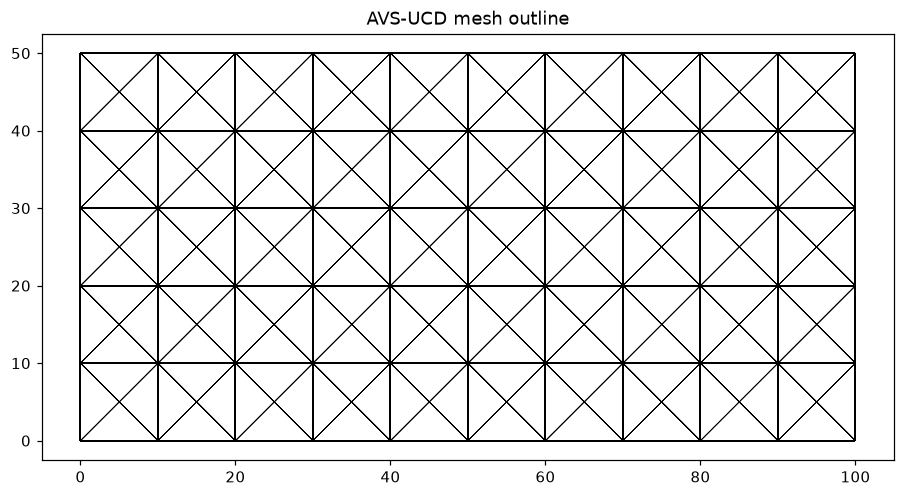

In [7]:
ds.plot_outline()
plt.title("AVS-UCD mesh outline")
show()

## A derived field: cell area

These engineering files usually carry **no cell data** we can colour by — so we compute one ourselves. `with_variable` attaches `face_areas` as a face-located variable, giving a non-destructive copy of the dataset that `plot` can render as a filled colour map.

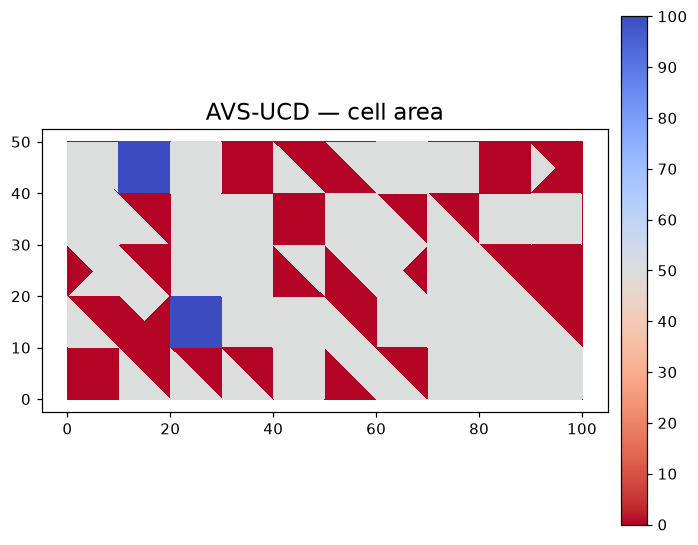

In [8]:
d2 = ds.with_variable("cell_area", np.asarray(ds.mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="AVS-UCD — cell area")
show()

The area map is noisy and self-overlapping — a direct visual symptom that a solid mesh has been forced into a flat surface. Compare this with the clean maps in the CGNS or MED notebooks.

## Treating the mesh as GIS

Because a `UgridDataset` is just nodes and polygonal faces, pyramids exposes the usual vector-GIS toolbox on it. First, every face as a GeoPandas polygon:

In [9]:
gdf = ds.to_geodataframe()
print(type(gdf).__name__, gdf.shape)
gdf.head()

GeoDataFrame (4800, 1)


,geometry
0,"POLYGON ((90 20, 100 10, 90 10, 100 20, 90 20))"
1,"POLYGON ((40 0, 30 10, 30 0, 40 10, 40 0))"
2,"POLYGON ((50 30, 50 20, 60 20, 50 20, 50 30))"
3,"POLYGON ((100 10, 90 0, 100 0, 90 10, 100 10))"
4,"POLYGON ((90 20, 90 10, 100 20, 100 10, 90 20))"


Being a real `GeoDataFrame`, it plots with GeoPandas directly — a filled view of every element footprint:

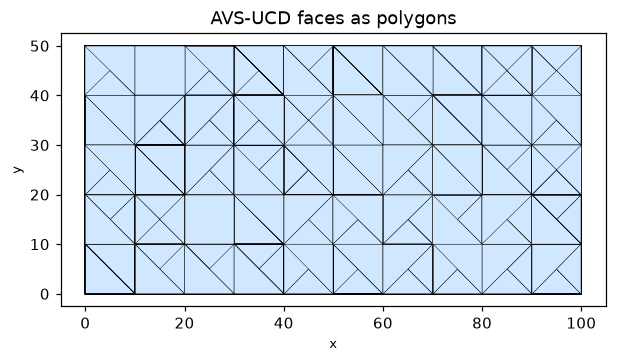

In [10]:
gdf.plot(edgecolor="black", linewidth=0.3, facecolor="#cfe8ff")
plt.title("AVS-UCD faces as polygons"); plt.gca().set_aspect("equal")
show()

### The outer boundary — and why it fails here

`bounding_polygon()` dissolves all faces into one polygon. On this projected tet mesh the faces self-intersect, so the geometry union raises a topology error. We catch it and report it — another concrete sign that this volumetric mesh does not form a valid 2D surface.

In [11]:
from shapely.errors import GEOSException
try:
    poly = ds.bounding_polygon()
    print("geometry type:", poly.geom_type)
except (GEOSException, ValueError) as e:
    print("bounding_polygon failed (expected for a projected tet mesh):")
    print("  ", type(e).__name__, str(e)[:80])

bounding_polygon failed (expected for a projected tet mesh):
   GEOSException TopologyException: side location conflict at 5 5. This can occur if the input ge


### Cropping to a bounding box

`crop(bbox=...)` returns a new `UgridDataset` with only the faces inside the box — handy for zooming into a region of a large mesh. We crop to the left half of the extent.

faces before / after: 4800 -> 2400


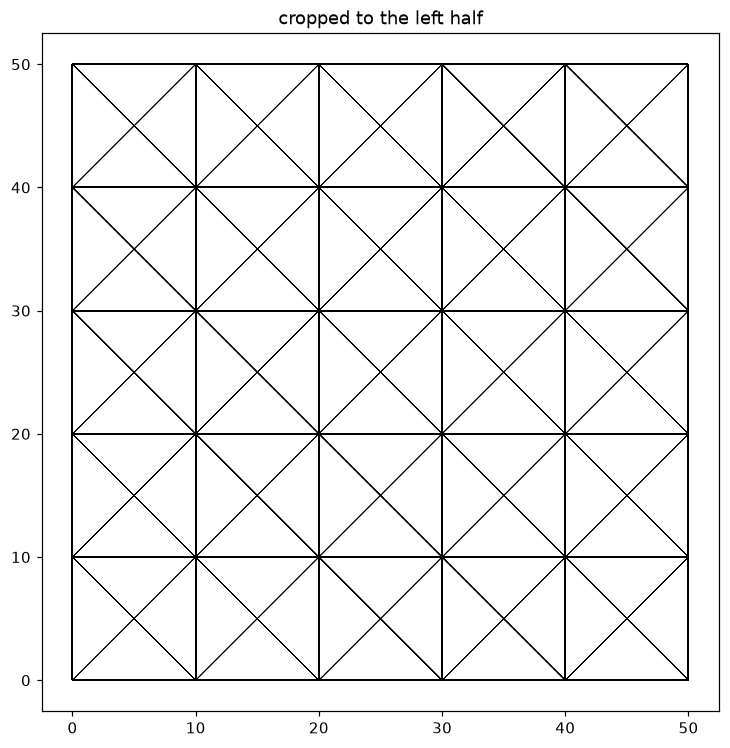

In [12]:
xmin, ymin, xmax, ymax = ds.bounds
half = ds.crop(bbox=(xmin, ymin, (xmin + xmax) / 2, ymax))
print("faces before / after:", ds.n_face, "->", half.n_face)
half.plot_outline(); plt.title("cropped to the left half"); show()

### The face-adjacency graph

`sparse_adjacency()` gives the face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels which faces are reachable from which. `plt.spy` shows the sparsity pattern — the fingerprint of how the faces are wired together.

adjacency: (4800, 4800) nnz = 10314
connected components: 604


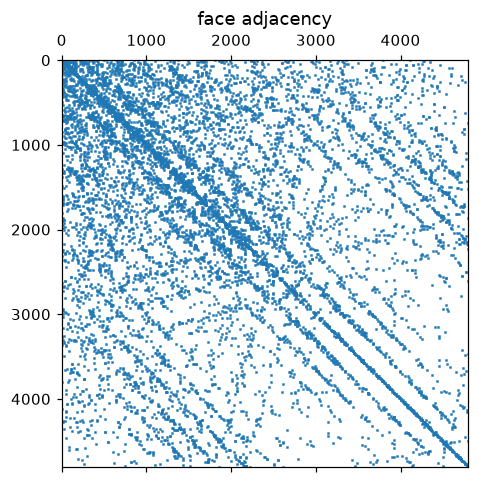

In [13]:
adj = ds.sparse_adjacency()
comp = np.asarray(ds.connected_components())
print("adjacency:", adj.shape, "nnz =", adj.nnz)
print("connected components:", np.unique(comp).size)
plt.spy(adj, markersize=0.6); plt.title("face adjacency"); show()

Here the graph is the most telling result: `connected_components` reports **hundreds** of components, not one. A valid surface would be a single patch; the fragmentation is the projection tearing the solid into disconnected slivers. The spy plot is correspondingly scattered.

### Why circumcenters are skipped here

The face table is 4-wide (not purely triangular), so `circumcenters()` raises `ValueError`. We catch it.

In [14]:
try:
    ds.circumcenters()
except ValueError as e:
    print("skipped (expected):", e)

skipped (expected): circumcenters is only defined for triangular meshes.


### Converting out: xarray and other drivers

`to_xarray()` hands the whole UGRID dataset to xarray (dimensions named the CF-UGRID way), and `to_file(path, driver=...)` re-serialises it through any writer in the driver table — here a round-trip to the `2dm` format in a temp file.

In [15]:
import tempfile
xd = ds.to_xarray()
print("xarray dims:", dict(xd.sizes))
out = Path(tempfile.gettempdir()) / "avsucd_roundtrip.2dm"
ds.to_file(out, driver="2dm")
print("wrote:", out.name, "| exists:", out.exists())

xarray dims: {'mesh2d_scalar': 1, 'mesh2d_nNodes': 1122, 'mesh2d_nFaces': 4800, 'mesh2d_nMaxFaceNodes': 4}
wrote: avsucd_roundtrip.2dm | exists: True


### What we cannot do here: reprojection & regridding

`to_crs(epsg)` reprojects between coordinate systems — but this mesh has **`crs=None`** (model-local coordinates, no datum), so there is nothing to reproject from; we skip it. Likewise `rasterize_like(...)` and `regrid(...)` map a *data field* onto a raster or another mesh; with no meaningful field and no georeferencing on an engineering mesh they are out of scope. These belong on georeferenced hydrodynamic meshes, not FEM/CFD decks.

## Takeaway

- `driver="avsucd"` reads an AVS-UCD ASCII mesh into a `UgridDataset`.
- This sample is **volumetric** (tetrahedra). Reading it as a 2D surface works but produces degenerate faces, a self-intersecting boundary, and a mesh that fragments into hundreds of components — all signalled by read-time warnings.
- The lesson: `UgridDataset` is a **surface** model. Feed it surface meshes (like the VTK, CGNS, MED, Nastran and Abaqus examples); a solid mesh is the wrong shape.
- `crs=None` throughout → no reprojection or regridding.